# HSA_G_002.py

## paramEKLD DOE  

repeat of B_039 buit with informative priors

In [1]:
import json
from pathlib import Path
import sys

sys.argv = [""]
import numpyro

numpyro.set_host_device_count(4)
import jax
import jax.numpy as jnp
import diffrax as dfx

# jax.config.update("jax_disable_jit",True)
jax.local_device_count()

import numpy as np
import matplotlib.pyplot as plt
import arviz as az
import ICIW_Plots

# plt.style.use("ICIWstyle")

In [2]:
from HSA_Mo_B_012 import (
    kinetics_model,
    predict,
    generate_synthetic_data,
    calculate_partial_pressures,
    validate_against_holdout,
    sample_prior,
    TRUE_PARAMS,
)

In [3]:
def evaluate_conditions(proposal, idata, key="posterior"):
    """
    Evaluate posterior predictions over temperature range at given conditions.

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions
        idata: ArviZ InferenceData with posterior samples

    Returns:
        predictions: Array of shape (100, n_samples) with rate predictions
    """
    # Extract conditions from proposal
    p = jnp.array([[proposal[1]]])
    c2h = jnp.array([[proposal[2]]])
    c2m = jnp.array([[proposal[3]]])
    c2w = jnp.array([[proposal[4]]])
    c2i = jnp.array([[proposal[5]]])
    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, c2m, c2w, c2i)

    # Temperature range for evaluation
    T = jnp.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # Generate posterior predictions
    predictions = predict(idata, T, p_i, key=key, num_samples=1000)

    return predictions


def evaluate_true_model(proposal):
    """
    Compute true model predictions (for comparison with posterior).

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions

    Returns:
        true_rates: Array of shape (100, 1) with true rate predictions
    """
    # Extract conditions
    p = jnp.array([[proposal[1]]])
    c2h = jnp.array([[proposal[2]]])
    c2m = jnp.array([[proposal[3]]])
    c2w = jnp.array([[proposal[4]]])
    c2i = jnp.array([[proposal[5]]])

    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, c2m, c2w, c2i)

    # Temperature range
    T = jnp.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # True model prediction
    _, _, true_rates = generate_synthetic_data(
        T, p, c2h, c2m, c2w, c2i, rel_noise_std=0.0
    )

    return true_rates


def plot_predictions(fig, ax, proposal, posterior_preds, true_preds, T_range):
    """
    Visualize posterior predictions vs true model with uncertainty.

    Args:
        proposal: Experimental conditions [T, p, c2h, f, c2i]
        posterior_preds: Posterior predictions (100, n_samples)
        true_preds: True model predictions (100, 1)
        T_range: Temperature values for x-axis
    """

    # Posterior mean
    ax.plot(
        T_range,
        posterior_preds.mean(axis=1),
        label="Posterior Mean",
        # color="blue",
    )

    # True model
    ax.plot(
        T_range,
        true_preds.squeeze(),
        label="True Model",
        color="black",
        linestyle="--",
        linewidth=2,
    )

    # 95% credible interval
    ax.fill_between(
        T_range,
        np.percentile(posterior_preds, 2.5, axis=1),
        np.percentile(posterior_preds, 97.5, axis=1),
        alpha=0.3,
        # color="blue",
        label="95% HDI",
    )

    ax.legend(loc="upper left")

    # Add condition text
    # condition_text = (
    #     f"Conditions:\n"
    #     f"p = {proposal[1]:.1f} bar\n"
    #     f"CO2/H2 = {proposal[2]:.2f}\n"
    #     f"Feed ratio = {proposal[3]:.1f}\n"
    #     f"CO2/Inert = {proposal[4]:.2f}"
    # )
    # ax.text(
    #     0.02,
    #     0.8,
    #     condition_text,
    #     transform=ax.transAxes,
    #     fontsize=9,
    #     verticalalignment="top",
    #     bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5),
    # )

    # Second y-axis for HDI width
    # ax2 = ax.twinx()
    # hdi_width = np.percentile(posterior_preds, 97.5, axis=1) - np.percentile(
    #     posterior_preds, 2.5, axis=1
    # )
    # ax2.plot(T_range, hdi_width, color="orange", alpha=0.7, linewidth=2)
    # ax2.set_ylabel("HDI Width", color="orange")
    # ax2.tick_params(axis="y", labelcolor="orange")

    # plt.title("Posterior Predictions vs True Model")
    # plt.tight_layout()
    return fig, ax

In [4]:
exp_run_name = "heroic-cipher"
data_path = Path(f"data/{exp_run_name}/")
sum_file = data_path / f"experiment_summary_{exp_run_name}.json"
trace_files = sorted(data_path.glob("trace_*.nc"))

In [5]:
idatas = []
for trace_file in trace_files:
    idata = az.from_netcdf(trace_file)
    idatas.append(idata)

In [6]:
for i, idata in enumerate(idatas):
    if i == 0:
        idata["prior"] = sample_prior(4000).prior.copy()
        print(idata)
    else:
        idata["prior"] = idatas[i - 1].posterior.copy()

<xarray.DataTree>
Group: /
├── Group: /posterior
│       Dimensions:       (chain: 8, draw: 4000, r_pred_dim_0: 1, r_pred_dim_1: 1)
│       Coordinates:
│         * chain         (chain) int64 64B 0 1 2 3 4 5 6 7
│         * draw          (draw) int64 32kB 0 1 2 3 4 5 ... 3995 3996 3997 3998 3999
│         * r_pred_dim_0  (r_pred_dim_0) int64 8B 0
│         * r_pred_dim_1  (r_pred_dim_1) int64 8B 0
│       Data variables:
│           A_h2          (chain, draw) float32 128kB ...
│           A_mix         (chain, draw) float32 128kB ...
│           A_oh          (chain, draw) float32 128kB ...
│           Ea_k          (chain, draw) float32 128kB ...
│           dH_h2         (chain, draw) float32 128kB ...
│           dH_mix        (chain, draw) float32 128kB ...
│           dH_oh         (chain, draw) float32 128kB ...
│           k0            (chain, draw) float32 128kB ...
│           r_pred        (chain, draw, r_pred_dim_0, r_pred_dim_1) float32 128kB ...
│           sigma_r     

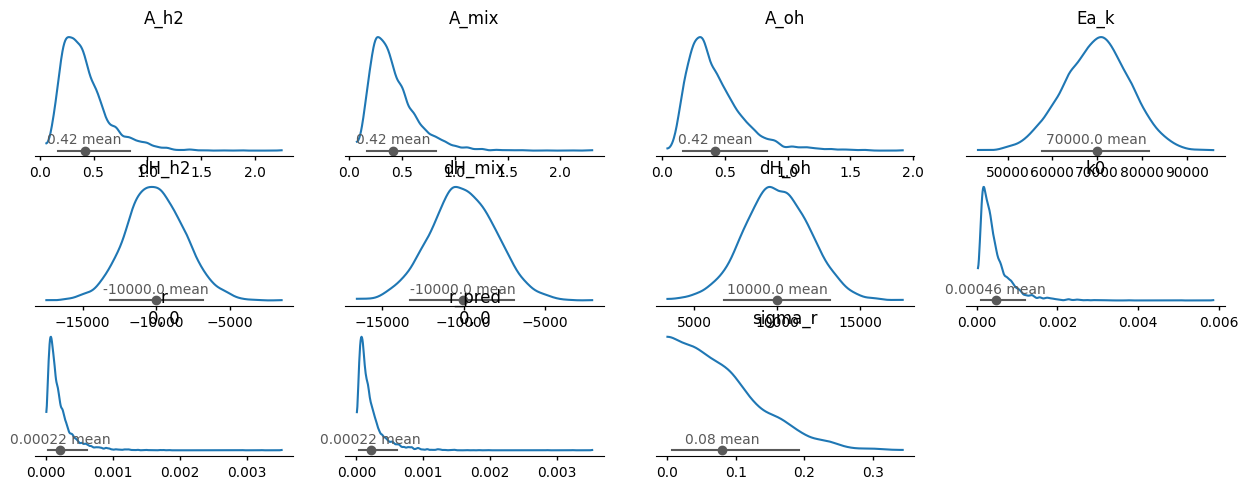

In [7]:
az.plot_dist(
    idatas[0],
    group="prior",
    # var_names=["k0", "Ea_k"],
)

In [8]:
display(idatas[5])

<xarray.DataTree>
Group: /
├── Group: /posterior
│       Dimensions:       (chain: 8, draw: 4000, r_pred_dim_0: 6, r_pred_dim_1: 1)
│       Coordinates:
│         * chain         (chain) int64 64B 0 1 2 3 4 5 6 7
│         * draw          (draw) int64 32kB 0 1 2 3 4 5 ... 3995 3996 3997 3998 3999
│         * r_pred_dim_0  (r_pred_dim_0) int64 48B 0 1 2 3 4 5
│         * r_pred_dim_1  (r_pred_dim_1) int64 8B 0
│       Data variables:
│           A_h2          (chain, draw) float32 128kB ...
│           A_mix         (chain, draw) float32 128kB ...
│           A_oh          (chain, draw) float32 128kB ...
│           Ea_k          (chain, draw) float32 128kB ...
│           dH_h2         (chain, draw) float32 128kB ...
│           dH_mix        (chain, draw) float32 128kB ...
│           dH_oh         (chain, draw) float32 128kB ...
│           k0            (chain, draw) float32 128kB ...
│           r_pred        (chain, draw, r_pred_dim_0, r_pred_dim_1) float32 768kB ...
│           sigma_r       (chain, draw) float32 128kB ...
│       Attributes:
│           created_at:                 2026-06-08T11:30:11.474542+00:00
│           arviz_version:              0.22.0
│           inference_library:          numpyro
│           inference_library_version:  0.19.0
├── Group: /log_likelihood
│       Dimensions:  (chain: 8, draw: 4000, data: 6, r_dim_1: 6)
│       Coordinates:
│         * chain    (chain) int64 64B 0 1 2 3 4 5 6 7
│         * draw     (draw) int64 32kB 0 1 2 3 4 5 6 ... 3994 3995 3996 3997 3998 3999
│         * data     (data) int64 48B 0 1 2 3 4 5
│         * r_dim_1  (r_dim_1) int64 48B 0 1 2 3 4 5
│       Data variables:
│           r        (chain, draw, data, r_dim_1) float32 5MB ...
│       Attributes:
│           created_at:                 2026-06-08T11:30:11.625987+00:00
│           arviz_version:              0.22.0
│           inference_library:          numpyro
│           inference_library_version:  0.19.0
├── Group: /sample_stats
│       Dimensions:    (chain: 8, draw: 4000)
│       Coordinates:
│         * chain      (chain) int64 64B 0 1 2 3 4 5 6 7
│         * draw       (draw) int64 32kB 0 1 2 3 4 5 6 ... 3994 3995 3996 3997 3998 3999
│       Data variables:
│           diverging  (chain, draw) bool 32kB ...
│       Attributes:
│           created_at:                 2026-06-08T11:30:11.492026+00:00
│           arviz_version:              0.22.0
│           inference_library:          numpyro
│           inference_library_version:  0.19.0
├── Group: /observed_data
│       Dimensions:  (data: 6)
│       Coordinates:
│         * data     (data) int64 48B 0 1 2 3 4 5
│       Data variables:
│           r        (data) float32 24B ...
│       Attributes:
│           created_at:                 2026-06-08T11:30:11.627689+00:00
│           arviz_version:              0.22.0
│           inference_library:          numpyro
│           inference_library_version:  0.19.0
└── Group: /prior
        Dimensions:       (chain: 8, draw: 4000, r_pred_dim_0: 5, r_pred_dim_1: 1)
        Coordinates:
          * chain         (chain) int64 64B 0 1 2 3 4 5 6 7
          * draw          (draw) int64 32kB 0 1 2 3 4 5 ... 3995 3996 3997 3998 3999
          * r_pred_dim_0  (r_pred_dim_0) int64 40B 0 1 2 3 4
          * r_pred_dim_1  (r_pred_dim_1) int64 8B 0
        Data variables:
            A_h2          (chain, draw) float32 128kB ...
            A_mix         (chain, draw) float32 128kB ...
            A_oh          (chain, draw) float32 128kB ...
            Ea_k          (chain, draw) float32 128kB ...
            dH_h2         (chain, draw) float32 128kB ...
            dH_mix        (chain, draw) float32 128kB ...
            dH_oh         (chain, draw) float32 128kB ...
            k0            (chain, draw) float32 128kB ...
            r_pred        (chain, draw, r_pred_dim_0, r_pred_dim_1) float32 640kB ...
            sigma_r       (chain, draw) float32 128kB ...
        Attributes:
            created_at:   

In [9]:
with open(sum_file, "r") as f:
    exp_summary = json.load(f)

In [10]:
proposals = np.array(exp_summary["trials"][-1]["observed"]["x"])
r_obs = np.array(exp_summary["trials"][-1]["observed"]["y"])

In [11]:
display(proposals)

array([[6.00000000e+02, 3.00000000e+00, 2.00000003e-01, 5.00000000e-01,
        1.00000000e+03, 5.00000007e-02],
       [4.50000000e+02, 3.00000000e+00, 4.00000000e+00, 1.00000000e+03,
        5.00000000e-01, 5.00000007e-02],
       [6.00000000e+02, 9.00000000e+00, 8.55502486e-01, 4.09845795e+02,
        5.07318207e+02, 8.66926372e-01],
       [6.00000000e+02, 9.00000000e+00, 4.00000000e+00, 1.00000000e+03,
        7.65848877e+02, 9.29601192e-01],
       [6.00000000e+02, 7.03014040e+00, 2.78660488e+00, 9.22171265e+02,
        4.20349609e+02, 1.00000000e+00],
       [4.50000000e+02, 9.00000000e+00, 2.00000003e-01, 1.00000000e+03,
        5.00000000e-01, 1.00000000e+00],
       [6.00000000e+02, 7.55223131e+00, 4.00000000e+00, 4.14618187e+01,
        4.91323242e+02, 1.00000000e+00],
       [4.50000000e+02, 9.00000000e+00, 8.10550332e-01, 3.94014816e+01,
        1.00000000e+03, 9.93205011e-01],
       [4.50000000e+02, 9.00000000e+00, 2.13030744e+00, 5.77671936e+02,
        9.07685852e+02, 

### Display the results:

In [12]:
from ipywidgets import interact, IntSlider


@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
    j=IntSlider(
        min=0, max=len(proposals) - 1, step=1, value=0, description="Proposal:"
    ),
)
def plot_interactive(i, j):
    fig = ICIW_Plots.figure(layout="double_column")
    ax = ICIW_Plots.make_rect_ax(
        fig,
        ax_width=7.5 * ICIW_Plots.cm2inch,
        ax_height=5.0 * ICIW_Plots.cm2inch,
        xlabel="$T$ / K",
        ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
        yscale="log",
        # ylim=(5e-6, 5e-4),
        # xlim=(450, 600),
    )
    test_res = evaluate_conditions(
        proposal=proposals[j],
        idata=idatas[i],
        key="posterior" if i > 0 else "prior",
    )
    true_res = evaluate_true_model(
        proposal=proposals[j],
    )
    plot_predictions(
        fig,
        ax,
        proposal=proposals[j],
        posterior_preds=test_res,
        true_preds=true_res,
        T_range=np.linspace(450, 600, 100),
    )
    ax.scatter(
        proposals[j, 0], r_obs[j], color="red", label="Observed Data Point", zorder=5
    )
    plt.show()

interactive(children=(IntSlider(value=0, description='Iteration:', max=31), IntSlider(value=0, description='Pr…

### Generate the exploration pattern

/tmp/ipykernel_96018/2292498082.py:81: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


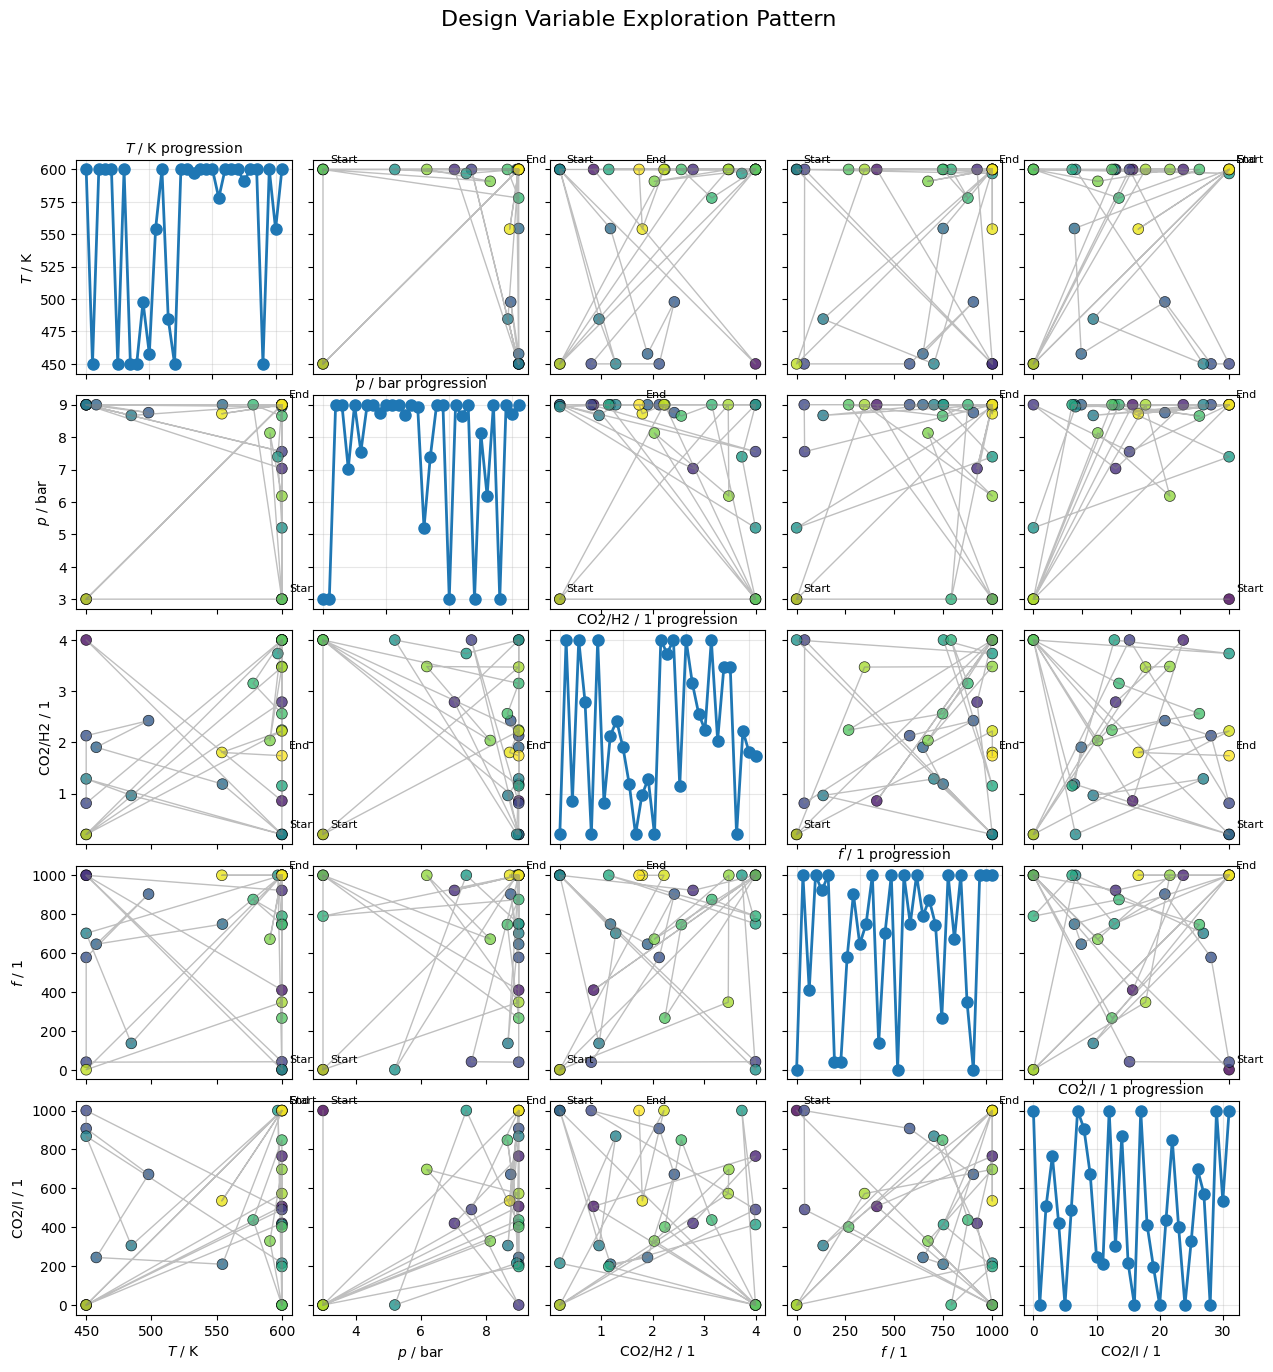

In [13]:
# create a 5x5 matrix plot with no gaps between the subplots
fig, axs = plt.subplots(
    5,
    5,
    figsize=(15, 15),
    sharex=False,
    sharey=False,
    gridspec_kw={"hspace": 0.1, "wspace": 0.1},
)

# Variable names for labeling
var_names = [r"$T$ / K", r"$p$ / bar", r"CO2/H2 / 1", r"$f$ / 1", r"CO2/I / 1"]

# Assuming proposals array exists with shape (n_experiments, 5)
n_experiments = proposals.shape[0]
experiment_order = np.arange(n_experiments)

for i in range(5):
    for j in range(5):
        ax = axs[i, j]

        if i == j:  # Diagonal: time series of each variable
            ax.plot(experiment_order, proposals[:, i], "o-", linewidth=2, markersize=8)
            ax.set_title(f"{var_names[i]} progression", fontsize=10, pad=5)
            ax.grid(True, alpha=0.3)
            if i == 4:  # Bottom row
                ax.set_xlabel("Experiment #")
        else:  # Off-diagonal: scatter plots
            # Color points by experiment order for temporal information
            scatter = ax.scatter(
                proposals[:, j],
                proposals[:, i],
                c=experiment_order,
                cmap="viridis",
                s=60,
                alpha=0.8,
                edgecolors="black",
                linewidth=0.5,
            )

            # Add trajectory lines
            ax.plot(
                proposals[:, j],
                proposals[:, i],
                "-",
                alpha=0.5,
                color="gray",
                linewidth=1,
            )

            # Label first and last points
            ax.annotate(
                "Start",
                (proposals[0, j], proposals[0, i]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=8,
            )
            if n_experiments > 1:
                ax.annotate(
                    "End",
                    (proposals[-1, j], proposals[-1, i]),
                    xytext=(5, 5),
                    textcoords="offset points",
                    fontsize=8,
                )

        # Set labels only on edges
        if i == 4:  # Bottom row
            ax.set_xlabel(var_names[j], fontsize=10)
        if j == 0:  # Left column
            ax.set_ylabel(var_names[i], fontsize=10)

        # Remove tick labels for inner plots
        if i < 4:
            ax.set_xticklabels([])
        if j > 0:
            ax.set_yticklabels([])

plt.suptitle("Design Variable Exploration Pattern", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

In [14]:
from ipywidgets import Dropdown

print(list(idatas[0].posterior.data_vars))


@interact(
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    )
)
def interactive(key):
    az.plot_dist(
        {str(idx):idata for idx, idata in enumerate(idatas)},
        group="posterior",
        var_names=key,
        point_estimate=None,
        # shade=0.2,
    )

['A_h2', 'A_mix', 'A_oh', 'Ea_k', 'dH_h2', 'dH_mix', 'dH_oh', 'k0', 'r_pred', 'sigma_r']


interactive(children=(Dropdown(description='Parameter:', index=7, options=('A_h2', 'A_mix', 'A_oh', 'Ea_k', 'd…

In [15]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
)
def interactive(i):
    axs = az.plot_pair(
        idatas[i],
        group="posterior",
        var_names=["k0", "Ea_k"],
        # kind=["scatter", "kde"],
        # point_estimate="median",
        # marginals=True,
    )
    # axs[2].set(
    #     xlim=(8e-5, 1e-3),
    #     # xscale="log",
    #     ylim=(30e3, 130e3),
    # )

interactive(children=(IntSlider(value=0, description='Iteration:', max=31), Output()), _dom_classes=('widget-i…

In [16]:
az.summary(idatas[-1], round_to=5)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A_h2,10.74169,1.27678,8.86740,12.91615,39023.39967,23507.69221,1.00019,0.00663,0.00507
A_mix,10.38594,1.32402,8.44788,12.65486,39591.05389,24455.11150,1.00011,0.00683,0.00529
A_oh,0.08019,0.02601,0.04472,0.12595,42617.27998,25090.15595,1.00017,0.00013,0.00011
Ea_k,-7862.87402,2454.71338,-11806.47494,-3937.58344,41498.76750,26729.99276,1.00061,12.04889,8.58290
dH_h2,-4072.07739,1513.86206,-6479.52627,-1650.61908,40243.75010,26192.21987,1.00044,7.54320,5.29255
dH_mix,-5083.86963,1565.99060,-7596.92516,-2576.28196,42076.69278,26178.14500,1.00045,7.63558,5.47689
dH_oh,9778.20215,1980.43762,6616.58461,12922.32029,40912.42234,26316.56447,1.00007,9.79327,6.98293
k0,0.10379,0.02363,0.07188,0.14544,39037.90109,23310.24320,1.00017,0.00013,0.00012
"r_pred[0, 0]",0.00016,0.00001,0.00015,0.00018,37843.15167,23268.70824,1.00035,0.00000,0.00000
"r_pred[1, 0]",0.00014,0.00001,0.00013,0.00016,39678.88646,25477.75853,1.00023,0.00000,0.00000


## load the holdout data

In [17]:
import xarray
test_data = xarray.open_dataset(Path("data/test_HSA_Da_B_002.nc"))
display(test_data)

<xarray.Dataset> Size: 120kB
Dimensions:    (sample: 1000, parameter: 6, species: 5)
Coordinates:
  * sample     (sample) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
  * parameter  (parameter) <U3 72B 'T' 'p' 'c2h' 'c2m' 'c2w' 'c2i'
  * species    (species) <U3 60B 'CO2' 'H2' 'H2O' 'CH4' 'I'
Data variables:
    samples    (sample, parameter) float64 48kB ...
    T          (sample) float64 8kB ...
    p          (sample, species) float64 40kB ...
    latent_r   (sample) float64 8kB ...
    obs_r      (sample) float64 8kB ...
Attributes:
    noise:    heteroscedastic
    sigma:    0.05

In [18]:
postdatas = []
for idata in idatas:
    postdata = validate_against_holdout(
        idata=idata,
        holdout=test_data,
        num_samples=985,
    )
    postdatas.append(postdata)

In [19]:
display(postdatas[0])

<xarray.DataTree>
Group: /
├── Group: /posterior
│       Attributes:
│           created_at:                 2026-06-09T08:02:22.987075+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.0.0
│           creation_library_language:  Python
├── Group: /posterior_predictive
│       Dimensions:  (chain: 1, draw: 985, obs: 1000)
│       Coordinates:
│         * chain    (chain) int64 8B 0
│         * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 978 979 980 981 982 983 984
│         * obs      (obs) int64 8kB 0 1 2 3 4 5 6 7 ... 992 993 994 995 996 997 998 999
│       Data variables:
│           r        (chain, draw, obs) float32 4MB 1.1e-06 2.087e-05 ... 3.357e-05
│           r_pred   (chain, draw, obs) float32 4MB 1.759e-06 2.202e-05 ... 3.347e-05
│       Attributes:
│           created_at:                 2026-06-09T08:02:22.987969+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.0.0
│           creation_library_language:  Python
└── Group: /observed_data
        Dimensions:       (obs: 1, r_dim_0: 1, r_dim_1: 1000, r_pred_dim_0: 1,
                           r_pred_dim_1: 1000)
        Coordinates:
          * obs           (obs) int64 8B 0
          * r_dim_0       (r_dim_0) int64 8B 0
          * r_dim_1       (r_dim_1) int64 8kB 0 1 2 3 4 5 6 ... 994 995 996 997 998 999
          * r_pred_dim_0  (r_pred_dim_0) int64 8B 0
          * r_pred_dim_1  (r_pred_dim_1) int64 8kB 0 1 2 3 4 5 ... 995 996 997 998 999
        Data variables:
            r             (obs, r_dim_0, r_dim_1) float64 8kB 9.144e-07 ... 3.195e-05
            r_pred        (obs, r_pred_dim_0, r_pred_dim_1) float64 8kB 9.32e-07 ... ...
        Attributes:
            created_at:                 2026-06-09T08:02:22.990782+00:00
            creation_library:           ArviZ
            creation_library_version:   1.0.0
            creation_library_language:  Python

In [20]:
proposals = test_data.samples.values
r_obs = test_data.obs_r.values
r_lat = test_data.latent_r.values


@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
    j=IntSlider(
        min=0, max=len(proposals) - 1, step=1, value=0, description="Proposal:"
    ),
)
def plot_interactive(i, j):
    fig = ICIW_Plots.figure(layout="double_column")
    ax = ICIW_Plots.make_rect_ax(
        fig,
        ax_width=7.5 * ICIW_Plots.cm2inch,
        ax_height=5.0 * ICIW_Plots.cm2inch,
        xlabel="$T$ / K",
        ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
        yscale="log",
    )
    test_res = evaluate_conditions(
        proposal=proposals[j],
        idata=idatas[i],
        key="posterior" if i > 0 else "prior",
    )
    true_res = evaluate_true_model(
        proposal=proposals[j],
    )
    plot_predictions(
        fig,
        ax,
        proposal=proposals[j],
        posterior_preds=test_res,
        true_preds=true_res,
        T_range=np.linspace(480, 600, 100),
    )
    fig = plt.gcf()
    axs = fig.axes
    axs[0].set(
        ylim=(0, 0.0006),
        xlabel="$T$ / K",
        xlim=(500, 600),
    )
    axs[0].scatter(
        proposals[j, 0], r_obs[j], color="red", label="Observed Data Point", zorder=5
    )
    axs[0].scatter(
        proposals[j, 0], r_lat[j], color="green", label="Latent Data Point", zorder=5
    )
    plt.show()

interactive(children=(IntSlider(value=0, description='Iteration:', max=31), IntSlider(value=0, description='Pr…

In [21]:
def bRMSE(postdata, var_name):
    true = postdata.observed_data[var_name].values
    pred = postdata.posterior_predictive[var_name].values
    res = true - pred
    rmse_vals = np.sqrt(np.mean(res**2, axis=2)).squeeze()
    rmse_da = xarray.DataArray(
        data=rmse_vals,
        dims=["draw"],
    )
    return rmse_da


RMSEs = {"r": [], "r_pred": []}
for postdata in postdatas:
    RMSE = bRMSE(postdata, "r_pred")
    RMSEs["r_pred"].append(RMSE)
    RMSE = bRMSE(postdata, "r")
    RMSEs["r"].append(RMSE)

RMSEar = {
    "r": np.array([rmse.values for rmse in RMSEs["r"]]),
    "r_pred": np.array([rmse.values for rmse in RMSEs["r_pred"]]),
}

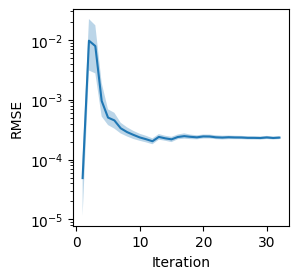

In [22]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="Iteration",
    ylabel="RMSE",
    yscale="log",
)
ax.plot(np.arange(1, len(RMSEar["r"]) + 1), RMSEar["r"].mean(axis=1))
ax.fill_between(
    np.arange(1, len(RMSEar["r"]) + 1),
    np.quantile(RMSEar["r"], 0.025, axis=1),
    np.quantile(RMSEar["r"], 0.975, axis=1),
    alpha=0.3,
)

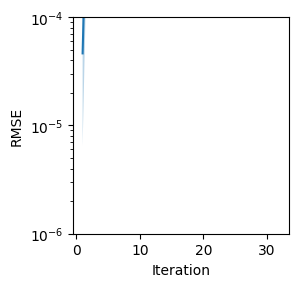

In [23]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="Iteration",
    ylabel="RMSE",
    yscale="log",
    ylim=(1e-6, 1e-4),
)
ax.plot(np.arange(1, len(RMSEar["r_pred"]) + 1), RMSEar["r_pred"].mean(axis=1))
ax.fill_between(
    np.arange(1, len(RMSEar["r_pred"]) + 1),
    np.quantile(RMSEar["r_pred"], 0.025, axis=1),
    np.quantile(RMSEar["r_pred"], 0.975, axis=1),
    alpha=0.3,
)

In [ ]:
keydict = {
    "k0": "k0",
    "Ea_k": "EA",
    "A_oh": "A_OH",
    "dH_oh": "H_OH",
    "A_h2": "A_H2",
    "dH_h2": "H_H2",
    "A_mix": "A_mix",
    "dH_mix": "H_mix",
}


@interact(
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    ),
)
def interactive(key):
    means = np.empty((0,))
    lhdi = np.empty((0,))
    uhdi = np.empty((0,))
    for idata in idatas:
        param_samples = idata.posterior[key].values.flatten()
        means = np.append(means, np.mean(param_samples))
        hdi = az.hdi(param_samples, prob=0.95)
        lhdi = np.append(lhdi, hdi[0])
        uhdi = np.append(uhdi, hdi[1])

    fig = ICIW_Plots.figure()
    ax = ICIW_Plots.make_square_ax(
        fig,
        ax_width=5.5 * ICIW_Plots.cm2inch,
        xlabel="Iteration",
        ylabel=f"{key}",
        # yscale="symlog",
    )
    if key != "sigma_r":
        ax.hlines(
            y=TRUE_PARAMS[keydict[key]],
            xmin=1,
            xmax=len(means),
            colors="gray",
            linestyles="dashed",
        )
    ax.plot(np.arange(1, len(means) + 1), means, label="Mean")
    ax.fill_between(
        np.arange(1, len(means) + 1),
        lhdi,
        uhdi,
        alpha=0.3,
        label="95% HDI",
    )
    ax.legend()

interactive(children=(Dropdown(description='Parameter:', index=7, options=('A_h2', 'A_mix', 'A_oh', 'Ea_k', 'd…